# 03. 작은 적응 실험: 범용(B0) · HCC-only(B1) · 미세조정(B2)

같은 HCC 세포주에서 **약물 8개**의 실측 반응만 학습에 쓸 수 있다고 하자. 세 가지 방법을 비교한다.

| 이름 | 출발점 | HCC 약물 8개로 학습 |
|---|---|---|
| B0 | source로 학습한 모델 | 하지 않음 |
| B1 | 무작위 초기값 | 함 |
| B2 | B0 | 함 (전체 파라미터 미세조정) |

이 노트북은 방법을 보여 주는 축소판이다(300 update, seed 하나, 검증 약물로 채점). 본 실험의 수치는 `RESULTS.md`에 있다. 시험(test) 약물은 여기서도 열지 않는다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("TB_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "transigen_adaptation_b1" else os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 160); pd.set_option("display.float_format", lambda v: f"{v:.3f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/transigen_adaptation_b1"
summ = json.load(open(f"{MAN}/splits_summary.json"))["targets"]
TARGET = next(t for t in ["HUH7", "JHH7", "JHH5"] if summ.get(t, {}).get("status", "excluded") != "excluded")
SPLIT = 1
print("example target:", TARGET, "| split seed:", SPLIT)

example target: HUH7 | split seed: 1


In [2]:
import torch
from src.transigen_adaptation_b1 import tsg_adapter as T
from src.transigen_adaptation_b1.data import Data
from src.transigen_adaptation_b1.adapt_target import TargetSet, source_checkpoint
D = Data(verify_hashes=False)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ts = TargetSet(D, TARGET, SPLIT, 8, dev)                          # 적응 약물 8개 + 검증 약물
sel = json.load(open(f"{MAN}/adapt_selection.json"))["selected"]
lr = {arm: sel[f"{TARGET}|{SPLIT}|{arm}"]["lr"] for arm in ["B1_scratch", "B2_finetune"]}
print("적응 행:", len(ts.rows_a), "(약물", ts.n_adapt_conditions, "개) | 검증 약물:", len(ts.cond_v), "| 본 실험에서 고른 학습률:", lr)

적응 행: 14 (약물 8 개) | 검증 약물: 19 | 본 실험에서 고른 학습률: {'B1_scratch': 0.001, 'B2_finetune': 0.001}


In [3]:
def run(arm, updates=300, every=25, seed=42):
    if arm == "B2_finetune":
        model, _ = T.load_checkpoint(source_checkpoint(seed)["checkpoint"], dev, seed=seed)
    else:
        model = T.build_model(seed, dev)
    T.seed_all(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr[arm], weight_decay=T.WEIGHT_DECAY)
    n = len(ts.rows_a); bs = min(32, n); gen = torch.Generator().manual_seed(seed)
    curve = [(0, ts.val_score(model)[0])]
    for step in range(1, updates + 1):
        b = torch.randperm(n, generator=gen)[:bs].to(dev)
        T.upstream_train_step(model, opt, ts.x0_a[b], ts.x1_a[b], ts.fp_a[b])   # 공개 코드의 loss를 그대로 사용
        if step % every == 0:
            curve.append((step, ts.val_score(model)[0]))
    return pd.DataFrame(curve, columns=["update", "val_delta_rmse"])

c1, c2 = run("B1_scratch"), run("B2_finetune")
b0 = c2.val_delta_rmse.iloc[0]                                    # update 0의 B2는 B0와 같은 모델이다
no_change = float(np.sqrt((ts.truth_v ** 2).mean(1)).mean())
pd.DataFrame({"update": c1["update"], "B1 (처음부터)": c1.val_delta_rmse, "B2 (미세조정)": c2.val_delta_rmse}).iloc[::2]

,update,B1 (처음부터),B2 (미세조정)
0,0,9.107,1.247
2,50,1.265,0.882
4,100,2.357,1.023
6,150,2.521,0.926
8,200,2.733,0.918
10,250,2.406,0.874
12,300,2.560,0.897


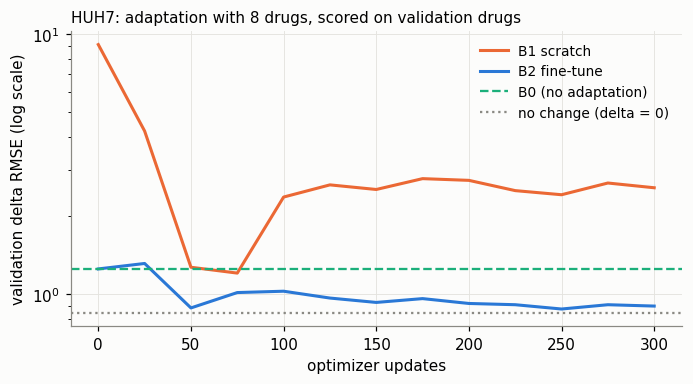

B0 1.2467 | 무변화 0.8452 | B1 최저 1.2015 | B2 최저 0.8739


In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(c1["update"], c1.val_delta_rmse, color=ORANGE, label="B1 scratch")
ax.plot(c2["update"], c2.val_delta_rmse, color=BLUE, label="B2 fine-tune")
ax.axhline(b0, color=AQUA, lw=1.5, ls="--", label="B0 (no adaptation)")
ax.axhline(no_change, color=GREY, lw=1.5, ls=":", label="no change (delta = 0)")
ax.set_yscale("log"); ax.set_xlabel("optimizer updates"); ax.set_ylabel("validation delta RMSE (log scale)")
ax.set_title(f"{TARGET}: adaptation with 8 drugs, scored on validation drugs", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()
print(f"B0 {b0:.4f} | 무변화 {no_change:.4f} | B1 최저 {c1.val_delta_rmse.min():.4f} | B2 최저 {c2.val_delta_rmse.min():.4f}")

## 읽는 법

- 세로축은 로그 척도다. B1은 발현의 절댓값(약 8~12)을 처음부터 다시 배워야 해서 출발점의 오차가 매우 크다.
- B2의 update 0 값이 B0다. 선이 그 아래로 내려가면 HCC 자료로 적응해서 좋아진 것이고, 올라가면 나빠진 것이다.
- 회색 점선(무변화)보다 위에 있는 모델은 "아무 변화도 없다"고 답하는 것보다 못하다.
- 본 실험에서는 검증 점수가 가장 좋은 update의 모델을 고른다. 그래서 검증 약물도 실제로 측정해야 하는 비용이다. "8개만 측정했다"고 말하려면 검증 약물 수를 함께 적어야 한다.
- 한 번의 축소 실행이다. 결론은 3개 분할 × 3개 seed의 시험 결과(`RESULTS.md`)로 판단한다.